calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
Global variables:
	PROJECT_PATH =  /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
	OPTICS_DATA_PATH =  /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	LITERA

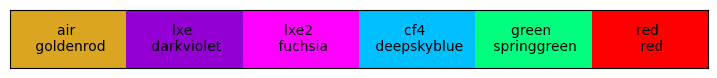

In [1]:
import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *
PrintDAAPSGlobalVariables()

# from lmfit import Model, Parameters
# import lmfit as lm
import inspect

from scipy import optimize as opt
from scipy.signal import find_peaks


# if you want this to be easier
#export PYTHONPATH="${PYTHONPATH}:/full/path/to/helpers"

import FittingFunctions as FFs
import PDE_fittingTools as SS
import iminuit
from iminuit import Minuit

import numpy as np
import matplotlib.pyplot as plt

# from PDEModel import * # this causes errors because of class naming same as module naming
from PDEModel.PhotonInfo import *
from PDEModel.OpticsDataLoader import *

from scipy.ndimage import gaussian_filter1d, uniform_filter
from scipy.optimize import curve_fit

from PDEModel import PDEStyle as MS
MS.ShowMyStyles()
ms = MS.MyStyleSet()
ms.SetMPLcolors()

from HPK_angularTools import *

In [2]:
rootFolder = PROJECT_PATH+"/literatureData/ref_data_guofu/"
print(rootFolder)

def GetFolderNameList(rootPath, includeStr = "",  equalStr=None):
    
    files = [f for f in os.listdir(rootPath) if os.path.isdir(os.path.join(rootPath, f))]
    if equalStr is not None:
        files = [f for f in files if f == equalStr]
    files = [f for f in files if includeStr in f]
    
    # check each folder exists and isn't empty
    for f in files:
        if os.path.exists(rootPath+f) and len(os.listdir(rootPath+f)) == 0:
            files.remove(f)
            print("something wrong with a folder!")
    return files


def GetFileName(rootPath, includeStr = "", secondIncludeStr = ""):
    
    files = [f for f in os.listdir(rootPath) if os.path.isfile(os.path.join(rootPath, f))]
    # print(files)
    files = [f for f in files if includeStr in f]
    files = [f for f in files if secondIncludeStr in f]
    
    # check single file and exists
    if len(files) != 1 or not os.path.exists(os.path.join(rootPath, files[0])):
        print("something wrong with a file!")
        print(files)
        return None
    
    return files[0]

/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/literatureData/ref_data_guofu/


---
### All Guofu's data

In [3]:
# taken manual-recursively from fit haha
dh_franta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-293K.txt"))

class systematics:
    def __init__(self):
        return

sys1 = systematics()

sys1.mcfwhm = 0.8
sys1.FF1 = 0.6
sys1.ppitch = 50

sys1.dh = dh_franta

hpkStr_wlen = "HPK1"
hpkStr_angle = "HPK_1"
# device 2 has FF 0.7
# pitch = 75

# device 1 has FF 0.6
# pitch = 50

someRefArgs = {"tOxide":16, "dh": sys1.dh,"FF":sys1.FF1, "shadowingH":4.5/sys1.ppitch, "smoothSigma": sys1.mcfwhm}
goodSd = 0.26
useFixedSD = False

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-293K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


['8deg', '18deg', '38deg', '48deg', '57deg']
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
angle:7.0, scaleDown = 0.18
322 322
angle:17.0, scaleDown = 0.17
322 322
angle:37.0, scaleDown = 0.18
322 322
angle:47.0, scaleDown = 0.44
322 322
angle:56.0, scaleDown = 0.89
361 361


Text(0.5, 1.0, 'nEXO (guofu) Reflectivity at fixed angles')

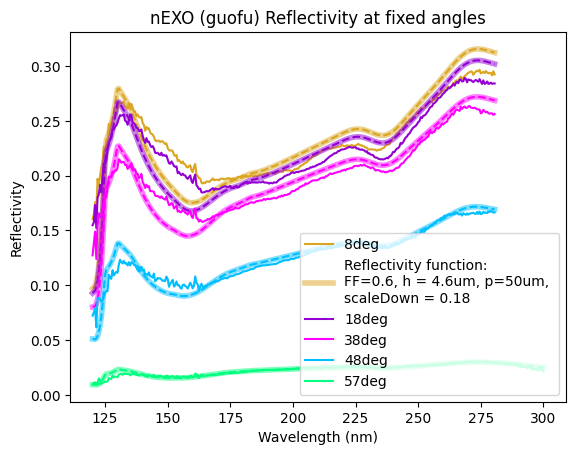

In [4]:
degreeFolders = GetFolderNameList(rootFolder, "deg")
degreeFolders = sorted(degreeFolders, key=lambda x: float(x.replace("deg", "")))
degreeNumbers = [float(x.replace("deg", "")) for x in degreeFolders]
print(degreeFolders)

sdVals_deg = []

ms.ResetColorCycle()
data_interpreted_wlen = []
for degrees in degreeFolders:
    
    fullPath = os.path.join(rootFolder, degrees)
    # print(fullPath)
    
    photon = PhotonInfo()
    
    hpk0 = GetFileName(fullPath, hpkStr_wlen, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_wlen, "pol90")
    
    x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
    x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
    
    xAvg = np.mean([x0, x90], axis=0)
    yAvg = np.mean([y0, y90], axis=0)/100
    
    degFloat = float(degrees.replace("deg", "")) - 1 # seems naming is off by 1 deg?
    
    plt.plot(xAvg, yAvg, color = ms.GetNextColor(), label=degrees)
    
    refArgs = {"wlen":xAvg, "theta1":degFloat, **someRefArgs}
    
    funcRef_pure = FFs.Reflectivity_wlen(scaleDown = 0, **refArgs)
    
    xmap = xAvg > 135
    st_std = np.std(yAvg[xmap]/funcRef_pure[xmap])
    sd = 1-np.average(yAvg[xmap]/funcRef_pure[xmap])
    print(f"angle:{degFloat}, scaleDown = {sd:.2f}")
    sdVals_deg.append([degFloat, sd, st_std])
    if useFixedSD:
        sd = goodSd
        
    funcRef = FFs.Reflectivity_wlen(scaleDown = sd, **refArgs)
        
    funcLabel = None
    if degFloat < 10:
        funcLabel = "Reflectivity function:\nFF=0.6, h = 4.6um, p=50um, \nscaleDown = {:.2f}".format(sd)
        
    plt.plot(xAvg, funcRef, color = ms.GetNextColor(1), linestyle="--")
    plt.plot(xAvg, funcRef, color = ms.GetNextColor(1), linewidth = 4, alpha=0.5, label = funcLabel)

    print(len(xAvg), len(yAvg))

plt.legend()

plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectivity")
plt.title("nEXO (guofu) Reflectivity at fixed angles")

# plt.xlim(150, 180)
# plt.ylim(0.15, 0.25)

---
### Fixed Wlen

['128nm', '165nm', '175nm', '193nm']
scaling 128.0 nm by sd: 0.1755
8 8
scaling 165.0 nm by sd: 0.1132
8 8
scaling 175.0 nm by sd: 0.1651
8 8
scaling 193.0 nm by sd: 0.2063
8 8


Text(0.5, 1.0, 'nEXO (guofu) Reflectivity at fixed angles')

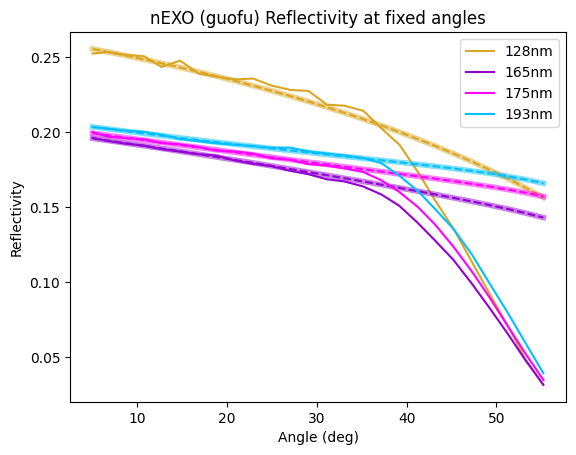

In [5]:
wlenFolders = GetFolderNameList(rootFolder, "nm")
wlenFolders = sorted(wlenFolders, key=lambda x: float(x.replace("nm", "")))
print(wlenFolders)

ms.ResetColorCycle()

sdVals_wlen = []
for wlenStr in wlenFolders:
    
    fullPath = os.path.join(rootFolder, wlenStr)
    # print(fullPath)
    
    photon = PhotonInfo()
    
    hpk0 = GetFileName(fullPath, hpkStr_angle, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_angle, "pol90")
    
    x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
    x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
    
    xAvg = np.mean([x0, x90], axis=0)
    yAvg = np.mean([y0, y90], axis=0)/100
    
    plt.plot(xAvg, yAvg, color = ms.GetNextColor(), label=wlenStr)
    
        
    ## doing Ref function
    wlenFloat = float(wlenStr.replace("nm", ""))
    refArgs = {"theta1":xAvg, "wlen":wlenFloat, **someRefArgs}
    
    funcRef_pure = FFs.Reflectivity_angle(scaleDown=0, **refArgs)
    
    ## scaling down
    xMap = xAvg < 20
    sd_std = np.std(yAvg[xMap]/funcRef_pure[xMap])
    sd = 1-np.sum(yAvg[xMap])/np.sum(funcRef_pure[xMap])
    # print(sd)
    print(f"scaling {wlenFloat} nm by sd: {sd:0.4f}")
    sdVals_wlen.append([wlenFloat, sd, sd_std])
    
    if useFixedSD:
        sd = goodSd
    
    funcRef = FFs.Reflectivity_angle(scaleDown=sd, **refArgs)
    plt.plot(xAvg, funcRef, color = ms.GetNextColor(1), linestyle = "--")
    plt.plot(xAvg, funcRef, color = ms.GetNextColor(1), linewidth=4, alpha=0.5)
    
    print(len(xAvg[xMap]), len(yAvg[xMap]))

    # interpolating    
    # dataInterpolated = interp1d(xAvg, yAvg, kind='cubic')
    # yInt = dataInterpolated(degreeNumbers[0])
    # print(f"wlen:{wlenFloat}, Interpolated value at {degreeNumbers[0]} deg: {yInt:0.2f}")
    
plt.legend()

plt.xlabel("Angle (deg)")
plt.ylabel("Reflectivity")
plt.title("nEXO (guofu) Reflectivity at fixed angles")

# plt.xlim(5, 15)
# plt.ylim(0.15, 0.25)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


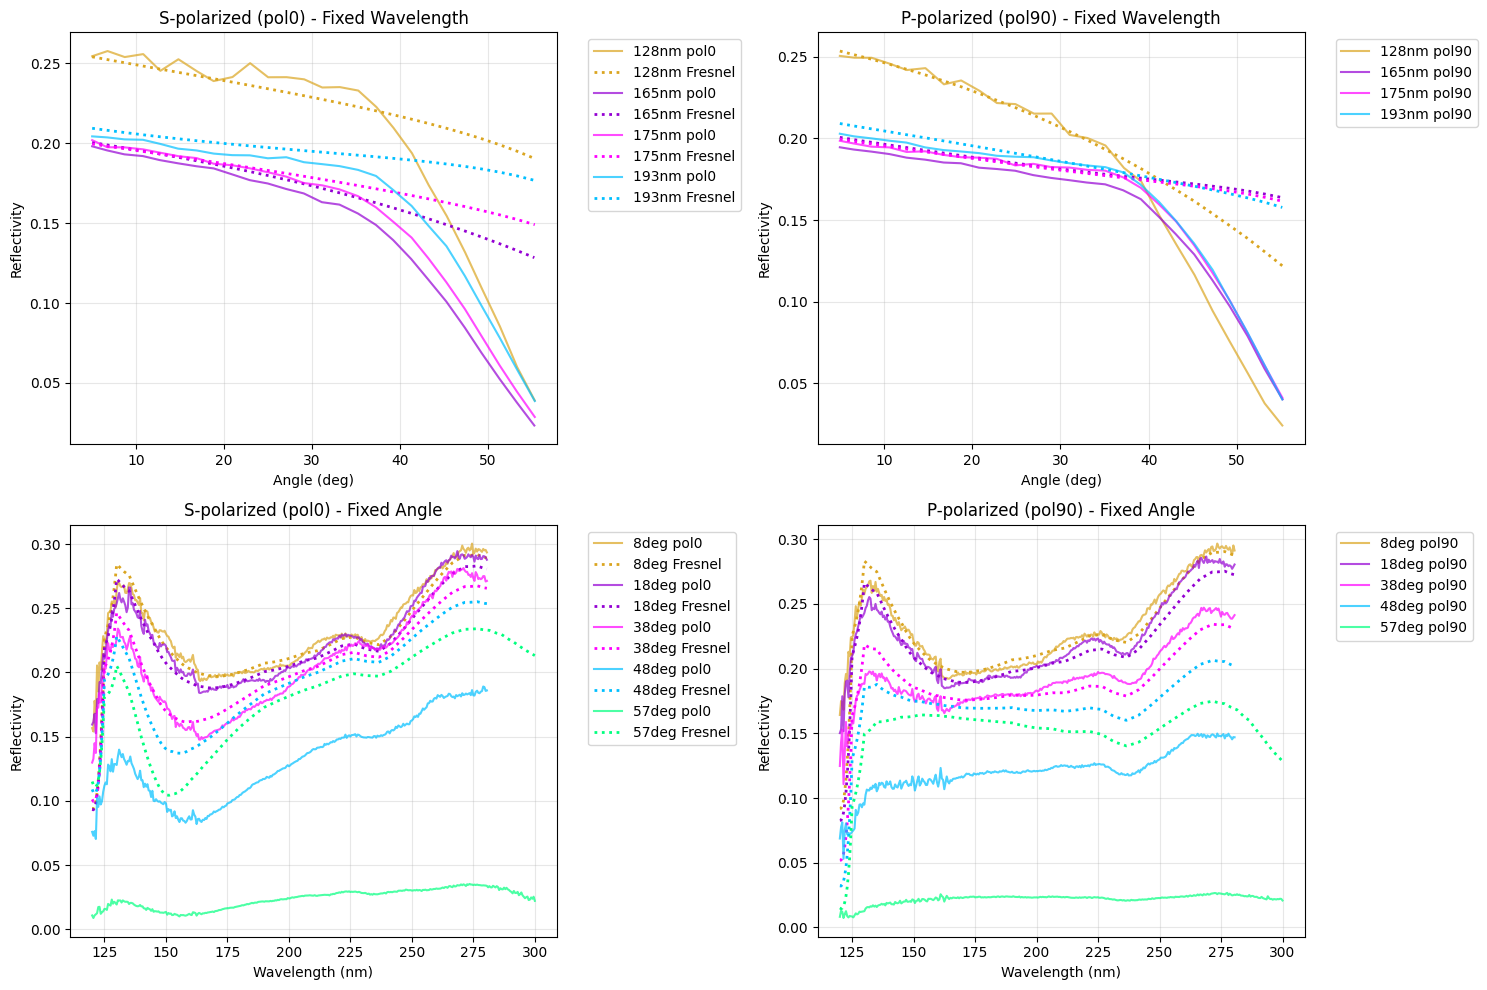

In [6]:
## plot 0 and 90 pol separately
def FullReflectivity_polarized(wlen, theta, thick_oxide, sd = 1.0, FF=0.6, relativeH=0.09):
  photon = PhotonInfo(wlen=wlen, theta_1=theta, dataHelper=None)
  
  Rp, Rs = photon.Wave_TotalReflection_polarized(thick_oxide=thick_oxide)
  
  ## xx Really all this needs to be encapsulated better in mathequations  
  relative_W = FFs.W_from_FF(FF)
  FF_theta = FF - 2 * FFs.FF_theta_relative_shadow(theta = theta, W = relative_W, H = relativeH)
  scaling = FF_theta * (1 - sd)

  return scaling * Rp, scaling * Rs

# Create subplots for better organization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

sdUse = 0.25
shadowUse = 4.5/50

# Plot fixed wavelength data (pol0 and pol90 separately)
ms.ResetColorCycle()
for wlenStr in wlenFolders:
    fullPath = os.path.join(rootFolder, wlenStr)
    wlenFloat = float(wlenStr.replace("nm", ""))
    
    hpk0 = GetFileName(fullPath, hpkStr_angle, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_angle, "pol90")
    
    if hpk0 and hpk90:
        x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
        x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
        
        col = ms.GetNextColor()
        ax1.plot(x0, y0/100, color=col, linestyle='-', alpha=0.7, label=f'{wlenStr} pol0')
        ax2.plot(x90, y90/100, color=col, linestyle='-', alpha=0.7, label=f'{wlenStr} pol90')
        
        # Add Fresnel predictions for this wavelength
        Rp, Rs = FullReflectivity_polarized(wlen=wlenFloat, theta=x0, thick_oxide=someRefArgs["tOxide"], sd=sdUse, FF=someRefArgs["FF"], relativeH=shadowUse)
        
        ax1.plot(x0, Rs, color=col, linestyle=':', alpha=1, linewidth=2, label=f'{wlenStr} Fresnel')
        ax2.plot(x90, Rp, color=col, linestyle=':', alpha=1, linewidth=2)

ax1.set_xlabel("Angle (deg)")
ax1.set_ylabel("Reflectivity")
ax1.set_title("S-polarized (pol0) - Fixed Wavelength")
ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax1.grid(True, alpha=0.3)

ax2.set_xlabel("Angle (deg)")
ax2.set_ylabel("Reflectivity")
ax2.set_title("P-polarized (pol90) - Fixed Wavelength")
ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.grid(True, alpha=0.3)

# Plot fixed angle data (pol0 and pol90 separately)
ms.ResetColorCycle()
for degrees in degreeFolders:
    fullPath = os.path.join(rootFolder, degrees)
    degFloat = float(degrees.replace("deg", "")) - 1
    
    hpk0 = GetFileName(fullPath, hpkStr_wlen, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_wlen, "pol90")
    
    if hpk0 and hpk90:
        x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
        x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
        
        col = ms.GetNextColor()
        ax3.plot(x0, y0/100, color=col, linestyle='-', alpha=0.7, label=f'{degrees} pol0')
        ax4.plot(x90, y90/100, color=col, linestyle='-', alpha=0.7, label=f'{degrees} pol90')
        
        Rp, Rs = FullReflectivity_polarized(wlen=x0, theta=degFloat, thick_oxide=someRefArgs["tOxide"], sd=sdUse, FF=someRefArgs["FF"], relativeH=shadowUse)
        ax3.plot(x0, Rs, color=col, linestyle=':', alpha=1, linewidth=2, label=f'{degrees} Fresnel')
        ax4.plot(x90, Rp, color=col, linestyle=':', alpha=1, linewidth=2)

ax3.set_xlabel("Wavelength (nm)")
ax3.set_ylabel("Reflectivity")
ax3.set_title("S-polarized (pol0) - Fixed Angle")
ax3.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax3.grid(True, alpha=0.3)

ax4.set_xlabel("Wavelength (nm)")
ax4.set_ylabel("Reflectivity")
ax4.set_title("P-polarized (pol90) - Fixed Angle")
ax4.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
## testing shadowing

ff = FFs.ff_from_FF(FF=0.6, pitch=50)
print(ff)
testFF = FFs.FF_theta_absolute(p = 50, ff=ff, h=2.5, theta=40)
print(testFF)

# might have a mistake w the shadowing functions
testW = FFs.W_from_FF(0.6)
testff = FFs.ff_from_FF(FF=0.6, pitch=50)

testFF = FFs.FF_theta_absolute(p=50, ff=testff, h=4.5, theta=40)
testFF_rel = 0.6 - FFs.FF_theta_relative_shadow(theta=40, W=testW, H=4.5/50)

print(testFF, testFF_rel)

5.635083268962915
0.5675018110264161
0.541503259847549 0.541503259847549


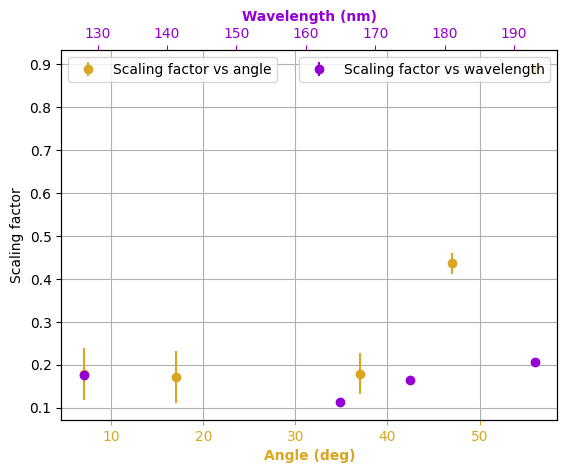

In [8]:
import matplotlib.pyplot as plt

ms.ResetColorCycle()

x1, y1, y1_std = zip(*sdVals_deg)
plt.errorbar(x1, y1, yerr=y1_std, marker = "o", color = ms.air.col, linestyle = "None", label="Scaling factor vs angle")

ax = plt.gca()
axTop = ax.twiny()

x2, y2, y2_std = zip(*sdVals_wlen)
axTop.errorbar(x2, y2, yerr=y2_std, marker = "o", color = ms.lxe.col, linestyle = "None", label="Scaling factor vs wavelength")
# print(sdVals_wlen)

ax.grid()
ax.legend()
ax.set_xlabel("Angle (deg)", color = ms.air.col, fontweight="bold")
ax.set_ylabel("Scaling factor")
ax.tick_params(axis="x", colors = ms.air.col)

axTop.legend()
axTop.tick_params(axis="x", colors = ms.lxe.col)
axTop.set_xlabel("Wavelength (nm)", color = ms.lxe.col, fontweight="bold")
# axTop.set_ylim(0.15, 0.6)

plt.show()

---
## Very global fitting

In [9]:
# nuisance parameters

# single SD parameter across all (good) datasets
# set shoulder as 35 deg

# reflectivity scaling down slightly increases with wavelength, which would be consistent with more diffraction into the Silicon??
# or maybe not if these are coming from two different things (diffraction around MS different than specular off Silicon)

In [10]:
print("list of needed args:", SS.GetNames(FFs.Reflectivity_angle))
fixedPars_ref = {"FF":sys1.FF1, "window":False, "smoothSigma":sys1.mcfwhm, "dh":sys1.dh, "mediumStr":"vacuum"}
shoulderCutoff = 30
shoulderCutoff_wlen = 40

wlen_cutoff = 0

error_abs_Fraction = 0.025 # 2.5% absolute error

wlen_reductionFactor = 1# relative data weights becomes 1:2 instead of 1:40 --> 8:322

fitFixedWlen = True
fitFixedAngle = True

list of needed args: ['wlen', 'theta1', 'tOxide', 'FF', 'scaleDown', 'shadowingH', 'window', 'smoothSigma', 'dh', 'mediumStr']


In [11]:
print("all degrees:", degreeFolders)
print("all wlen:", wlenFolders)
sys1.skipWlen = []
skipDeg = []

floatPars_ref = {"scaleDown":0.2, "tOxide":18, "shadowingH":4./sys1.ppitch}
floatBounds_ref = {"scaleDown":(0.01, 1), "tOxide":(1, 50), "shadowingH":(0.01, 0.99)}

# making both datasets (start with fixed wlen)
wlenFolders = GetFolderNameList(rootFolder, "nm")
wlenFolders = sorted(wlenFolders, key=lambda x: float(x.replace("nm", "")))

dataDicts_ToFit = []
dataDict_notReduced = []

##### Loading the fixed wavelength data #####
for wlenStr in wlenFolders:
    
    fullPath = os.path.join(rootFolder, wlenStr)
    wlenFloat = float(wlenStr.replace("nm", ""))
    
    if wlenFloat in sys1.skipWlen:
        print("skipping", wlenStr)
        continue

    hpk0 = GetFileName(fullPath, hpkStr_angle, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_angle, "pol90")
    
    x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
    x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
    
    xAvg = np.mean([x0, x90], axis=0)
    yAvg = np.mean([y0, y90], axis=0)/100
    xMap = xAvg < shoulderCutoff
    xFit = xAvg[xMap]
    yFit = yAvg[xMap]
    yErrFit = np.repeat(error_abs_Fraction, len(yFit))

    dataFitDict = {"theta1":xFit, "yVals":yFit, "yErrs":yErrFit, "wlen":wlenFloat}
    
    dataDict_notReduced.append({"theta1":xAvg, "yVals":yAvg, "yErrs":np.repeat(error_abs_Fraction, len(yAvg)), "wlen":wlenFloat})

    # plt.errorbar(xFit, yFit, yErrFit, fmt='o', label=wlenStr)
    if fitFixedWlen:
        dataDicts_ToFit.append(dataFitDict)

##### Loading the fixed angle data #####
degreeFolders = GetFolderNameList(rootFolder, "deg")
degreeFolders = sorted(degreeFolders, key=lambda x: float(x.replace("deg", "")))
degreeNumbers = [float(x.replace("deg", "")) for x in degreeFolders]

for degrees in degreeFolders:
    
    fullPath = os.path.join(rootFolder, degrees)
    degFloat = float(degrees.replace("deg", "")) - 1 # seems naming is off by 1 deg?
    
    if degFloat + 1 in skipDeg:
        print("skipping", degrees, "via skip")
        continue
    
    hpk0 = GetFileName(fullPath, hpkStr_wlen, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_wlen, "pol90")
    
    x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
    x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
    
    xAvg = np.mean([x0, x90], axis=0)[::wlen_reductionFactor]
    yAvg = (np.mean([y0, y90], axis=0)/100)[::wlen_reductionFactor]
    yErrFit = np.repeat(error_abs_Fraction, len(yAvg))
    
    xMap = xAvg > wlen_cutoff
    xAvg = xAvg[xMap]
    yAvg = yAvg[xMap]
    yErrFit = yErrFit[xMap]
    
    if degFloat > shoulderCutoff_wlen:
        print("skipping", degrees, "via shoulder")
        continue
    
    dataFitDict = {"wlen":xAvg, "yVals":yAvg, "yErrs":yErrFit, "theta1":degFloat}
    dataDict_notReduced.append({"wlen":xAvg, "yVals":yAvg, "yErrs":yErrFit, "theta1":degFloat})
    if fitFixedAngle:
        dataDicts_ToFit.append(dataFitDict)

SS.CheckDataSetKey_consistent(dataDicts_ToFit, True);

print("\n------\ndata used:")
for d in dataDicts_ToFit:
    if not hasattr(d["wlen"], "__len__"):
        print(d["wlen"], "nm")
    elif not hasattr(d["theta1"], "__len__"):
        print(d["theta1"], "deg")

all degrees: ['8deg', '18deg', '38deg', '48deg', '57deg']
all wlen: ['128nm', '165nm', '175nm', '193nm']
skipping 48deg via shoulder
skipping 57deg via shoulder
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed

------
data used:
128.0 nm
165.0 nm
175.0 nm
193.0 nm
7.0 deg
17.0 deg
37.0 deg


In [12]:
print("------ Fitting conditions check ------")
a = SS.CheckAllConditions_forResiduals(func=FFs.Reflectivity_either, dataObj=dataDicts_ToFit, dFixed=fixedPars_ref, dFloat=floatPars_ref,
                                   dBounds=floatBounds_ref, yNames=("yVals", "yErrs"), verbose=False)
xo_ref1, xo_ref1_names = SS.BuildX0(floatDict=floatPars_ref, functionToFit=FFs.Reflectivity_angle)
xo_Bounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_ref, functionToFit=FFs.Reflectivity_angle)
if a:
    print("passed fitting check")


------ Fitting conditions check ------
passed fitting check


In [13]:
initGuess = SS.GenericResiduals(x0 = xo_ref1, dataObj=dataDicts_ToFit, functionToFit=FFs.Reflectivity_either, fixedArgs_dict = fixedPars_ref, verbose=False, yNames=("yVals", "yErrs"))
print("Initial guess:", initGuess)

result_ref1 = iminuit.minimize(SS.GenericResiduals, x0=xo_ref1, bounds = xo_Bounds, args=(fixedPars_ref, dataDicts_ToFit, FFs.Reflectivity_either), method='migrad')
fRes = SS.GenericResiduals(x0 = result_ref1.x, dataObj=dataDicts_ToFit, functionToFit=FFs.Reflectivity_either, fixedArgs_dict = fixedPars_ref, verbose=False, yNames=("yVals", "yErrs"))

print("final result:", fRes)

Initial guess: 268.3043120791523
final result: 247.06409952408887


In [14]:
print(result_ref1)
resDict_ref1 = SS.GetResDict(result_ref1, xo_ref1_names)
resDictErrors_A_UV = SS.GetResErrorDict(result_ref1, xo_ref1_names)

print(resDict_ref1)
print("errors:", resDictErrors_A_UV)

  message: Optimization terminated successfully.
  success: True
      fun: 247.06409952408887
        x: [ 1.764e+01  1.836e-01  8.877e-02]
 hess_inv: ┌────┬────────────────────────────┐
           │    │       x0       x1       x2 │
           ├────┼────────────────────────────┤
           │ x0 │  0.00764 0.008e-3    -8e-6 │
           │ x1 │ 0.008e-3 1.14e-05    -8e-6 │
           │ x2 │    -8e-6    -8e-6 9.53e-06 │
           └────┴────────────────────────────┘
     nfev: 66
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 247.1                      │              Nfcn = 66               │
           │ EDM = 6.65e-07 (Goal: 0.0001)    │            time = 0.8 sec            │
           ├──────────────────────────────────┼─────────────────────

In [15]:
print("------- Final result from Reflectivity fit -------")
for key in resDict_ref1.keys():
    if "xide" in key:
        print(f"oxide thickness: {resDict_ref1[key]:0.2f} +/- {resDictErrors_A_UV[key]:0.2f} nm")
    elif "shadow" in key:
        print(f"shadowing height: {resDict_ref1[key]*sys1.ppitch:0.1f} +/- {resDictErrors_A_UV[key]*sys1.ppitch:0.1f} um")
    else:
        print(f"{key}: {resDict_ref1[key]:0.3f} +/- {resDictErrors_A_UV[key]:0.3f}")    

------- Final result from Reflectivity fit -------
oxide thickness: 17.64 +/- 0.09 nm
scaleDown: 0.184 +/- 0.003
shadowing height: 4.4 +/- 0.2 um


fixed Pars: {'FF': 0.6, 'window': False, 'smoothSigma': 0.8, 'dh': <PDEModel.OpticsDataLoader.OpticsData object at 0x16608cb10>, 'mediumStr': 'vacuum'}
float pars: {'tOxide': 17.639, 'scaleDown': 0.1836, 'shadowingH': 0.0888}


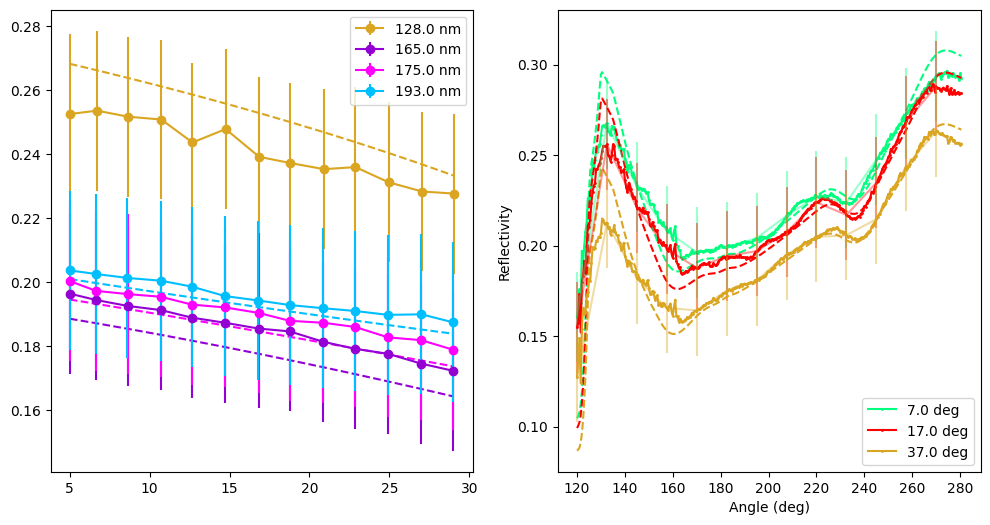

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))


print("fixed Pars:", fixedPars_ref)
print("float pars:", resDict_ref1)

allArgs = {**fixedPars_ref, **resDict_ref1}

ms.ResetColorCycle()

for d in dataDicts_ToFit:
    col = ms.GetNextColor()
    y = d['yVals']
    yErr = d['yErrs']
    if hasattr(d['theta1'], "__len__"):
        x = d['theta1']
        funcRef = FFs.Reflectivity_either(wlen = d['wlen'], theta1=x, **allArgs)
        
        ax1.errorbar(x, y, yErr, marker='o', linestyle='-', color=col, label = f"{d['wlen']} nm")
        ax1.plot(x, funcRef, linestyle='--', color=col)
    else:
        x = d['wlen']
        funcRef = FFs.Reflectivity_either(wlen = x, theta1=d['theta1'], **allArgs)
        
        ax2.plot(x, y, marker='o', linestyle='-', color=col, label = f"{d['theta1']} deg", markersize = 1)
        ax2.errorbar(x[::25], y[::25], yErr[::25], linestyle='-', alpha = 0.4, color=col)
        
        ax2.plot(x, funcRef, linestyle='--', color=col)

   
ax1.legend()
ax2.legend()
 
plt.xlabel('Angle (deg)')
plt.ylabel('Reflectivity')
plt.show()

---
## LXe data (single curve)

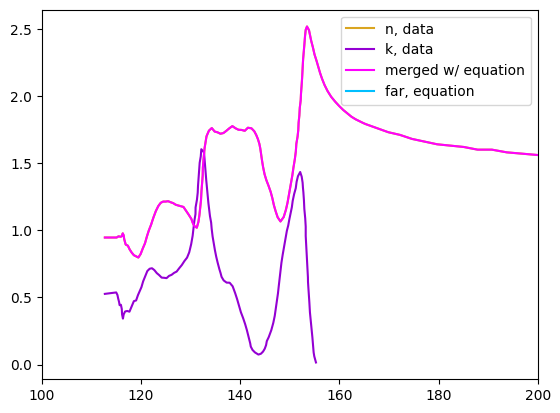

In [17]:
# getting LXe data


from eXT_andToyModels_nb.nobleFunctions import *
rho_lxe = density_t(273-110)
wlen_n_far = np.arange(400, 1100, 5)
lxe_n_Far = n_index_rho(lamb = wlen_n_far, rho = rho_lxe)

## Load in LXe data
xe_n_xeV, xe_n_y = np.loadtxt(os.path.join(PROJECT_PATH, "opticsData", "LXe-n_vs_Ephoton.txt"), delimiter=",", skiprows=0, unpack = True)
xe_k_xeV, xe_k_y = np.loadtxt(os.path.join(PROJECT_PATH, "opticsData", "LXe-k_vs_Ephoton.txt"), delimiter=",", skiprows=0, unpack = True)
lxe_wlen_merged, lxe_n_merged = np.loadtxt(os.path.join(PROJECT_PATH, "opticsData", "lxe_n_merged.txt"), delimiter="\t", skiprows=0, unpack = True)

wlen_lxe_n = 1240/xe_n_xeV
wlen_lxe_k = 1240/xe_k_xeV

plt.plot(wlen_lxe_n, xe_n_y, label="n, data")
plt.plot(wlen_lxe_k, xe_k_y, label="k, data")

plt.plot(lxe_wlen_merged, lxe_n_merged, label="merged w/ equation")
plt.plot(wlen_n_far, lxe_n_Far, label="far, equation")

plt.xlim(100, 200)

plt.legend()
plt.show()

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


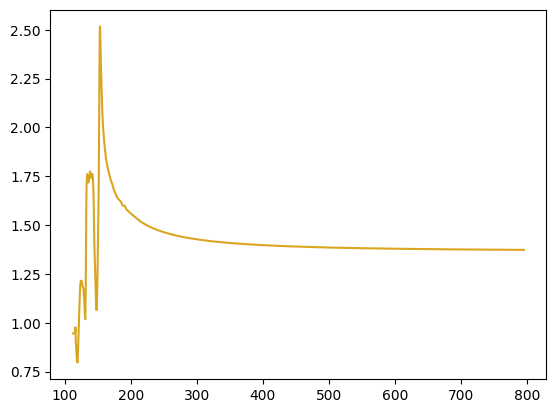

In [18]:
# finterp_lxe_n = interp1d(wlen_lxe_n, xe_n_y, kind='linear')

od = OpticsData()
a, b = od.Load_LXe_nData()

plt.plot(a, b, label="n, data")

In [19]:
bamaPDE_angle = np.loadtxt(os.path.join(LITERATURE_DATA_PATH, "alabama_relativePDE_angle.csv"), delimiter=",", unpack=True, skiprows=1)

bamaRef_angle = np.loadtxt(os.path.join(LITERATURE_DATA_PATH, "alabama_reflectivity_LXe.csv"), delimiter=",", unpack=True, skiprows=1)

# plt.plot(bamaPDE_angle[0], bamaPDE_angle[1]/np.max(bamaPDE_angle[1]), label="Alabama relative PDE vs angle")

In [20]:
testPDE_new = FFs.PDE_allArgs_Angle_parametrized_medium_shadowing(wlen = 175, theta1=0, FF=0.6, tOxide=17.2, dp_star=1.0, Xpn=1.8e3, dw_star=5e3,
                                                              voltage=4, Ve=1.6, Vh=20, Ae=1.0, Ah=1.0,
                                                              Temperature = None, smoothSigma=None, quantum = True, dh = None, window=False,
                                                              shadowingH=4.5/50, mediumStr="LXe")

print("test PDE at 0 deg:", testPDE_new)

test PDE at 0 deg: 0.18588009496675922


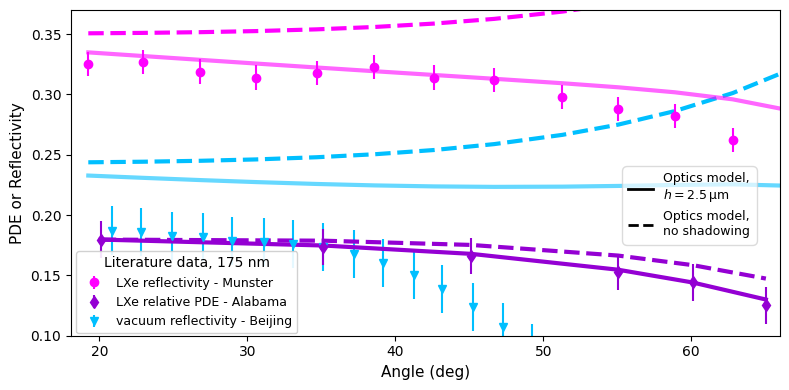

In [28]:
from matplotlib.lines import Line2D

xLXe_munster, yLXe_munster = np.loadtxt(PROJECT_PATH+"/literatureData/LXe_munster_vuv4_webPlot.csv", delimiter=",", unpack=True)

# Set up axes from the start
fig, ax1 = plt.subplots(figsize=(8, 4))
lsShadow = "-"
lsNoShadow = "--"

plw = 3

lxeDict = {**fixedPars_ref, **resDict_ref1}
lxeDict["mediumStr"] = "lxe"
lxeDict["scaleDown"] = 0.0
lxeDict["wlen"] = 177
lxeDict["theta1"] = xLXe_munster
lxeDict["tOxide"] = 17.2
lxeDict["shadowingH"] = 2.5/sys1.ppitch
lxeDict["window"] = False

## air data
airDict = lxeDict.copy()
airDict["mediumStr"] = "vacuum"
scaleAir = 0.

##### Beijing vacuum data and models #####
for d in dataDict_notReduced:
    y = d['yVals']
    yErr = d['yErrs']
    if hasattr(d['theta1'], "__len__") and np.abs(d['wlen'] - 178) < 5:
        x = d['theta1']
        qmap = x > min(xLXe_munster)
        lineChina = ax1.errorbar(x[qmap], y[qmap], 0.8*yErr[qmap], marker='v', linestyle='None', label = f"vacuum reflectivity - Beijing", color = ms.cf4.col)

# vacuum, shadow
funcRef_air = FFs.Reflectivity_angle(**airDict)
ax1.plot(xLXe_munster, (1-scaleAir)*funcRef_air, label="Model, air, shadow", color = ms.cf4.col, linewidth=plw, linestyle = lsShadow, alpha = 0.6)

# vacuum, no shadow
copyAirDict = airDict.copy()
copyAirDict["shadowingH"] = None
funcRef_noShadow_air = FFs.Reflectivity_angle(**copyAirDict)
ax1.plot(xLXe_munster, (1-scaleAir)*funcRef_noShadow_air, label="Model, air, no shadow", linestyle=lsNoShadow, linewidth=plw, color = ms.cf4.col)

# lineBamaRef = ax1.errorbar(bamaRef_angle[0][bMask2], bamaRef_angle[1][bMask2], 0.015, marker = "s", linestyle = "None", label="LXe - Alabama")
# bMask2 = bamaRef_angle[0] >= np.min(xLXe_munster)

##### plot Munster LXe reflectivity data and models #####
funcRef_lxe = FFs.Reflectivity_angle(**lxeDict)
ax1.plot(xLXe_munster, funcRef_lxe, label="Model, LXe, shadow", color = ms.lxe2.col, linewidth=plw, linestyle = lsShadow, alpha = 0.6)

lineMunster = ax1.errorbar(xLXe_munster, yLXe_munster, 0.01, linestyle="None", marker="o", label="LXe reflectivity - Munster", color = ms.lxe2.col)

# Plot no-shadowing models on ax1
copyLXeDict = lxeDict.copy()
copyLXeDict["shadowingH"] = None
funcRef_noShadow_lxe = FFs.Reflectivity_angle(**copyLXeDict)
ax1.plot(xLXe_munster, funcRef_noShadow_lxe, label="Model, LXe, no shadow", linewidth = plw, linestyle=lsNoShadow, color = ms.lxe2.col)
# ax1.plot(xLXe_munster, xLXe_munster**2)


##### plotting Alabama PDE and models #####
bamaMask = bamaPDE_angle[0] >= np.min(xLXe_munster)
bamaPDE_x = bamaPDE_angle[0][bamaMask]

lxePDE_default = FFs.PDE_allArgs_Angle_parametrized_medium_shadowing(wlen = 175, theta1=bamaPDE_x, FF=0.6, tOxide=17.2, dp_star=1.0, Xpn=1.8e3, dw_star=5e3,
                                                              voltage=4, Ve=1.8, Vh=20, Ae=1.0, Ah=1.0,
                                                              Temperature = None, smoothSigma=None, quantum = True, dh = None, window=False,
                                                              shadowingH=2.5/50, mediumStr="LXe")

lxePDE_default_noShadow = FFs.PDE_allArgs_Angle_parametrized_medium_shadowing(wlen = 175, theta1=bamaPDE_x, FF=0.6, tOxide=17.2, dp_star=1.0, Xpn=1.8e3, dw_star=5e3,
                                                              voltage=4, Ve=1.8, Vh=20, Ae=1.0, Ah=1.0,
                                                              Temperature = None, smoothSigma=None, quantum = True, dh = None, window=False,
                                                              shadowingH=None, mediumStr="LXe")

lineLXePDE_default = ax1.plot(bamaPDE_x, lxePDE_default, marker = None, linestyle = lsShadow, linewidth=plw, color = ms.lxe.col, label="PDE (LXe)")
lineLXePDE_default_noShadow = ax1.plot(bamaPDE_x, np.max(lxePDE_default)/np.max(lxePDE_default_noShadow) * lxePDE_default_noShadow, marker = None, linestyle = lsNoShadow, linewidth=plw, color = ms.lxe.col, label="Modelled PDE (LXe, no shadow)")

lineBamaPDE = ax1.errorbar(bamaPDE_x, np.max(lxePDE_default) * bamaPDE_angle[1][bamaMask]/np.max(bamaPDE_angle[1][bamaMask]), 0.015,
                           marker = "d", linestyle = "None", color = ms.lxe.col, label="LXe relative PDE - Alabama")

###### 420 and 800 nm models (no shadowing) ######
hpkDict = {"dp_star":1.0, "Xpn":2.3e3, "dw_star":13.6e3, "Ve":1.8, "Vh":16.76, "Ae":1.0, "Ah":1.0}
richerXangle = np.arange(0, 80, 2.5)

pde420_noShadow = FFs.PDE_allArgs_Angle_parametrized_medium_shadowing(wlen = np.array([420]), theta1=richerXangle, FF=0.6, tOxide=17.2, voltage=4, **hpkDict,
                                                              Temperature = 160, smoothSigma=None, quantum = False, dh = None, window=True,
                                                              shadowingH=None, mediumStr="LAr")
pde800_noShadow = FFs.PDE_allArgs_Angle_parametrized_medium_shadowing(wlen = np.array([800]), theta1=richerXangle, FF=0.6, tOxide=17.2, voltage=4, **hpkDict,
                                                              Temperature = 160, smoothSigma=None, quantum = False, dh = None, window=True,
                                                              shadowingH=None, mediumStr="LAr")

# linePDE420 = ax1.plot(richerXangle, pde420_noShadow, marker=None, linestyle=lsNoShadow, linewidth=plw, alpha=0.7, color="green", label = "420 nm (this work)")
# linePDE800 = ax1.plot(richerXangle, pde800_noShadow, marker=None, linestyle=lsNoShadow, linewidth=plw, alpha=0.7, color=ms.red.col, label = "800 nm (this work)")

##################
# Set labels and styling
fsize = 9
ax1.set_xlabel("Angle (deg)", fontsize = fsize+2)
ax1.set_ylabel("PDE or Reflectivity", fontsize = fsize+2)

# Make ax1 tick text larger
ax1.tick_params(axis='both', which='major')

##### custom legends #####
legend_literature = [
  lineMunster,
  # lineBamaRef,
  lineChina
]

leg_models = [
  Line2D([0], [0], color='black', linestyle='-', linewidth = plw-1, label='Optics model,\n' + r'$h=2.5\,\mathrm{μm}$'),
  Line2D([0], [0], color='black', linestyle='--', linewidth = plw-1, label='Optics model,\nno shadowing')
]

leg_PDE = [
  lineBamaPDE,
  # linePDE420[0],
  # linePDE800[0]
]

leg_allData = [
  lineMunster,
  lineBamaPDE,
  lineChina
]


# Create first legend (line styles) and add it to the plot
# leg1 = ax1.legend(title="Literature data (175 nm)", handles=legend_literature, loc='upper left', fontsize=fsize, bbox_to_anchor=(18.5, 0.15), bbox_transform=ax1.transData, framealpha=0.9, facecolor='white')
# leg2 = ax1.legend(title="Relative PDE", handles=leg_PDE, loc='upper left', fontsize=fsize, bbox_to_anchor=(48, 0.26), bbox_transform=ax1.transData, framealpha=0.95)

legData = ax1.legend(title="Literature data, 175 nm", handles=leg_allData, loc='upper left', title_fontsize = fsize+1, fontsize=fsize, bbox_to_anchor=(18, 0.175), bbox_transform=ax1.transData, framealpha=0.9, facecolor='white')

leg3 = ax1.legend(handles = leg_models, loc='upper left', fontsize=fsize, bbox_to_anchor=(55, 0.2452), bbox_transform=ax1.transData, framealpha=0.7, fancybox=True)
leg3.get_frame().set_boxstyle('round', pad=0.1, rounding_size=0.4)

# for L in (leg1, leg2, leg3):
#   L.get_frame().set_facecolor('white')
#   L.get_frame().set_alpha(1.0)
#   L.set_zorder(100)
  
ax1.add_artist(legData)
# ax1.add_artist(leg1)
# ax1.add_artist(leg2)
# ax1.add_artist(leg3)

# Add parameter text box
bbox = dict(facecolor='red', alpha=0.4, boxstyle='round', pad=0.7)
shFl = 0 if lxeDict["shadowingH"] is None else lxeDict["shadowingH"]*sys1.ppitch
plText = f"Model Parameters:\noxide ={lxeDict['tOxide']:.1f} nm\nresistor h = {shFl:.1f} um"
# ax1.text(35, 0.03, plText, bbox=bbox, fontdict={'size': 10})

# Set limits
# ax1.set_ylim(ax1.get_ylim()[0], 0.4)
ax1.set_ylim(0.1, 0.37)
ax1.set_xlim(min(bamaPDE_x)*0.9, 66)

plt.tight_layout()
plt.show()

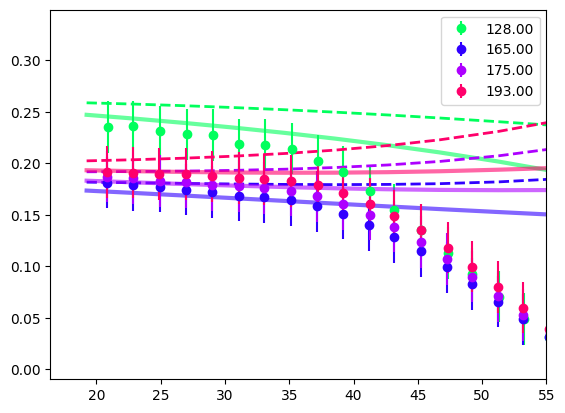

In [ ]:
## plotting all the angular data vs our model
for d in dataDict_notReduced:
    y = d['yVals']
    yErr = d['yErrs']
    if hasattr(d['theta1'], "__len__"):
        x = d['theta1']
        wlen = d['wlen']
        
        col = MS.map_value_to_hsv(wlen, 80, 200)
        
        qmap = x > min(xLXe_munster)
        plt.errorbar(x[qmap], y[qmap], yErr[qmap], marker='o', linestyle="None", label = f"{wlen:.2f}", color = col)
        lxeDict["wlen"] = wlen
        airDict["wlen"] = wlen

        funcRef_air = FFs.Reflectivity_angle(**airDict)
        scale = 0.21
        plt.plot(xLXe_munster, (1-scale)*funcRef_air, color = col, linewidth = 3, alpha = 0.6)
        
        airDict_noShadow = airDict.copy()
        airDict_noShadow["shadowingH"] = None
        funcRef_air_noShadow = FFs.Reflectivity_angle(**airDict_noShadow)
        plt.plot(xLXe_munster, (1-scale)*funcRef_air_noShadow, color = col, linestyle="--", linewidth = 2)

plt.xlim(plt.gca().get_xlim()[0], 55)
plt.legend()